# 23 — El catálogo de variables y su validación en varios años

## Pregunta y alcance

Los cuadernos 13 a 21 incorporaron variables y fuentes externas al pronóstico del triage: clima, salud pública
de la ciudad, estado de la red de aseguradores y regímenes de fondo como El Niño. Cada una se midió con su propio
diseño y casi siempre sobre 2026. Este cuaderno reúne todo en un solo lugar y responde dos preguntas: qué variables
quedan en el modelo y con qué criterio, y si lo medido se sostiene cuando el modelo se evalúa en años distintos,
con contextos distintos, y con probabilidades que no prometan más de lo que los datos permiten (un acierto de
60-70 % en sube/baja es creíble; uno de 80-90 % no).

La evaluación es siempre hacia adelante: para cada año de prueba (2023, 2024, 2025 y 2026) el modelo se entrena
únicamente con los años anteriores. Se mide el acierto en «sube» o «baja» frente a lo que esperaría el calendario, el
BSS (la mejora del error cuadrático de la probabilidad frente a una probabilidad constante), la cobertura del
intervalo del 80 % y el MAPE. La regla para aceptar una capa o una técnica se fijó antes de calcular: debe mejorar
a la base en al menos 3 de los 4 años.

## Contenido

1. El catálogo de variables y el criterio de entrada.
2. Los contextos que el entrenamiento llegó a ver.
3. Por qué mezclar días al azar infla el resultado.
4. Lo que dice la literatura sobre validar y entrenar series de este tipo.
5. Un error de método del motor, hallado en la validación multianual, y su corrección.
6. La validación de cada capa en cuatro años.
7. Las técnicas de entrenamiento de la literatura, probadas una por una.
8. Calibración de las probabilidades.
9. La corrección aplicada al motor con reentrenamiento semanal.
10. Entrenar con fechas escogidas y con pesos por tipo de contexto.
11. El contexto con compuerta.
12. La confirmación de la compuerta con origen rodante.
13. La respuesta semanal: método y alcance.
14. Conclusiones y límites.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, lightgbm as lgb
from matplotlib import pyplot as plt
import pronostico as pr, indices as ix
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})

---
# 1. El catálogo de variables y el criterio de entrada

La tabla recoge cada grupo de variables, su fuente, si se conoce el día en que se predice, desde cuándo hay
historia, la evidencia que lo respalda y la decisión. El criterio de entrada no es que la variable muestre un
efecto, sino que cumpla tres condiciones: se conoce el día de la predicción, tiene historia suficiente y no se
construyó mirando 2026.

In [2]:
CAT = pd.DataFrame([
 # capa, variable, que mide, fuente, al predecir, desde, evidencia, decision
 ["Calendario", "día de la semana, festivo, puente, víspera, día después, quincena, vacaciones, Semana Santa, Navidad, fin de año, regreso a clases", "el ritmo social", "calendario de Colombia", "por adelantado", "2020", "72 % de la variación diaria (cuaderno 14)", "ENTRA: es el control"],
 ["Calendario", "COVID fuerte y parcial, paro nacional 2021", "episodios únicos", "fechas fijas", "por adelantado", "2020", "hunden la notificación de todo (cuaderno 20)", "ENTRA como marca, no como predictor"],
 ["Estación", "3 armónicos del año", "la época del año", "la fecha", "por adelantado", "—", "mayo concentra picos (cuaderno 14)", "ENTRA"],
 ["Nivel", "media de 28 días", "el nivel de la red", "triage del hospital", "hasta ayer", "2020", "sigue los escalones (cuaderno 15)", "ENTRA"],
 ["Memoria", "desvío de la última semana, del último día y del mismo día de la semana pasada", "la inercia de corto plazo", "triage del hospital", "hasta ayer", "2020", "autocorrelación de +0,26 a 1 día (cuaderno 14)", "ENTRA"],
 ["Clima", "4 índices de estado (soleado y seco frente a nublado y húmedo; cálido; viento; sol con humedad)", "cómo está el tiempo", "ERA5 + NASA POWER", "hasta ayer (observado)", "2010", "IRA de la ciudad +6-7 %; triage +1-2 % (cuaderno 17)", "ENTRA"],
 ["Clima", "3 índices de cambio brusco", "si el tiempo cambió de golpe", "ERA5 + NASA POWER", "hasta ayer", "2010", "81 % de los cambios (cuaderno 17)", "ENTRA"],
 ["Clima", "racha seca; días desde la última semana muy lluviosa", "sequía y lluvia reciente", "NASA POWER", "hasta ayer", "2010", "mayores +4,6 % tras lluvia y adultos +2,8 % tras racha seca en 2022-2024; no se confirman en 2025-2026 (cuaderno 21)", "ENTRA"],
 ["Clima", "lluvia del ERA5", "—", "Open-Meteo Archive", "—", "—", "10 veces lo real, correlación −0,02 (cuaderno 17)", "FUERA: está rota"],
 ["Salud pública", "familia respiratoria (IRA total, 0-4, 60+)", "la ola respiratoria de la ciudad", "SIVIGILA + Power BI", "semana anterior", "2012", "mueve el respiratorio del hospital +10-14 % (cuaderno 13)", "ENTRA"],
 ["Salud pública", "violencias y agresiones; salud mental e intoxicaciones; materno-perinatal; inmunoprevenibles", "las otras urgencias de la ciudad", "SIVIGILA + Power BI", "semana anterior", "2015", "familias casi independientes, r ≤ 0,19 (cuaderno 19)", "ENTRA"],
 ["Salud pública", "familia digestiva (EDA)", "diarrea de la ciudad", "solo microdatos", "NO: ~8 meses tarde", "2012", "+15,7 % con sequía (cuaderno 19)", "FUERA hasta tener fuente a tiempo"],
 ["Salud pública", "IRAG hospitalizada", "gravedad respiratoria", "microdatos / rutinaria", "no empalma en 2026", "2012", "—", "FUERA"],
 ["Red de salud", "peso de Nueva EPS y de SURA (28 días)", "el estado de la red", "triage por asegurador", "hasta ayer", "2020", "dos aseguradoras son el 80-90 % (cuaderno 18)", "ENTRA"],
 ["Red de salud", "cambio de 28 días de Nueva EPS y del resto; Herfindahl", "si la red se mueve", "triage por asegurador", "hasta ayer", "2020", "la caída de Nueva EPS es de acceso (cuaderno 18)", "ENTRA"],
 ["Red de salud", "resolución de la Supersalud sobre Nueva EPS (30 días)", "intervenciones y cambios", "Supersalud (capturado)", "fecha pública", "2024", "coincide con el escalón de noviembre de 2025 (cuaderno 18)", "ENTRA"],
 ["Red de salud", "afiliados por EPS en Manizales; uso por afiliado", "tamaño y acceso de cada EPS", "MinSalud (capturado)", "1 mes", "2025-07", "−20 % afiliados y −60 % triage en Nueva EPS (cuaderno 18)", "FUERA por ahora: 14 meses de historia"],
 ["Red de salud", "quejas por EPS (PQRD), giros de ADRES", "barreras y pagos", "Supersalud, ADRES", "1-2 meses", "2017 / 2020", "—", "FUERA por ahora: sin captura automática"],
 ["Regímenes", "ONI, El Niño, La Niña", "el clima de fondo del año", "NOAA (capturado)", "2 meses de retraso", "1950", "La Niña sube violencias y salud mental; El Niño +3,6 % (cuaderno 20)", "ENTRA; El Niño queda como hipótesis prospectiva"],
 ["Regímenes", "sismo fuerte (7 días)", "sismos M ≥ 4,5 a menos de 150 km", "USGS", "minutos", "2010", "sin efecto, con 40 episodios (cuaderno 20)", "ENTRA (pesa poco)"],
 ["Eventos", "Feria, eventos de Manizales, fiestas de Caldas, días especiales", "aglomeraciones", "calendarios propios", "por adelantado", "2020", "0,5 % de la ganancia (cuaderno 15)", "FUERA del total; la Feria ya se refleja en el calendario"],
 ["Motivo", "motivo de consulta limpio (NLP)", "el desenlace específico", "NLP/", "—", "2025", "es desenlace, no predictor (la serie existe solo desde 2025)", "FUERA: es desenlace, no entrada"],
], columns=["capa", "variable", "qué mide", "fuente", "¿se sabe al predecir?", "desde", "evidencia", "decisión"])
pd.set_option("display.max_colwidth", 120)
dec = CAT["decisión"].str.split(r"[:;]| por ").str[0].str.split().str[0]
print("Filas del catálogo:", len(CAT), "| ENTRA:", int((dec == "ENTRA").sum()), "| FUERA:", int((dec == "FUERA").sum()))
CAT

Filas del catálogo: 22 | ENTRA: 15 | FUERA: 7


,capa,variable,qué mide,fuente,¿se sabe al predecir?,desde,evidencia,decisión
0,Calendario,"día de la semana, festivo, puente, víspera, día después, quincena, vacaciones, Semana Santa, Navidad, fin de año, re...",el ritmo social,calendario de Colombia,por adelantado,2020,72 % de la variación diaria (cuaderno 14),ENTRA: es el control
1,Calendario,"COVID fuerte y parcial, paro nacional 2021",episodios únicos,fechas fijas,por adelantado,2020,hunden la notificación de todo (cuaderno 20),"ENTRA como marca, no como predictor"
2,Estación,3 armónicos del año,la época del año,la fecha,por adelantado,—,mayo concentra picos (cuaderno 14),ENTRA
3,Nivel,media de 28 días,el nivel de la red,triage del hospital,hasta ayer,2020,sigue los escalones (cuaderno 15),ENTRA
4,Memoria,"desvío de la última semana, del último día y del mismo día de la semana pasada",la inercia de corto plazo,triage del hospital,hasta ayer,2020,"autocorrelación de +0,26 a 1 día (cuaderno 14)",ENTRA
5,Clima,4 índices de estado (soleado y seco frente a nublado y húmedo; cálido; viento; sol con humedad),cómo está el tiempo,ERA5 + NASA POWER,hasta ayer (observado),2010,IRA de la ciudad +6-7 %; triage +1-2 % (cuaderno 17),ENTRA
6,Clima,3 índices de cambio brusco,si el tiempo cambió de golpe,ERA5 + NASA POWER,hasta ayer,2010,81 % de los cambios (cuaderno 17),ENTRA
7,Clima,racha seca; días desde la última semana muy lluviosa,sequía y lluvia reciente,NASA POWER,hasta ayer,2010,"mayores +4,6 % tras lluvia y adultos +2,8 % tras racha seca en 2022-2024; no se confirman en 2025-2026 (cuaderno 21)",ENTRA
8,Clima,lluvia del ERA5,—,Open-Meteo Archive,—,—,"10 veces lo real, correlación −0,02 (cuaderno 17)",FUERA: está rota
9,Salud pública,"familia respiratoria (IRA total, 0-4, 60+)",la ola respiratoria de la ciudad,SIVIGILA + Power BI,semana anterior,2012,mueve el respiratorio del hospital +10-14 % (cuaderno 13),ENTRA


**Lectura.** El catálogo tiene 22 grupos de variables. **Entran 15**: el calendario (2 grupos), la estación, el nivel y la memoria, el clima (3 grupos: índices de estado, índices de cambio brusco y sequía o lluvia reciente), la salud pública (2 grupos), la red de aseguradores (3 grupos) y los regímenes (2 grupos). **Quedan fuera 7**:
- la lluvia del ERA5, porque está rota (10 veces lo real y correlación de −0,02 con la observada);
- la familia digestiva y la IRAG hospitalizada, porque no existen el día en que se predice;
- los eventos en el total, porque el calendario ya los recoge (la Feria se refleja en él);
- los afiliados por EPS, que tienen 14 meses de historia, y las quejas y giros, que no tienen captura automática;
- el motivo de consulta, que es el desenlace específico y no puede ser entrada.

El criterio de entrada no es que la variable tenga efecto, sino que se conozca el día de la predicción, tenga historia suficiente y no se haya construido mirando 2026. Que además aporte al pronóstico del total no lo establece esta tabla: lo establecen las secciones 6, 7, 10 y 11, en cuatro años distintos.

---
# 2. Los contextos que el entrenamiento llegó a ver

Para cada año de prueba se cuenta cuántos días de cada contexto tenía el entrenamiento (todo lo anterior, desde
2020) y cuántos trae el año que se predice. Un contexto que el modelo no vio en el entrenamiento no se puede
aprender, y un contexto que no aparece en el año de prueba no se puede validar.

In [3]:
pr.usar("h"); y, cal = pr.cargar()
PAS = ix.contexto_holistico(cal.index).reindex(y.index)
R = ix.regimenes_diarios().reindex(y.index)
ctx = pd.DataFrame({"El Niño": R.el_nino, "La Niña": R.la_nina, "COVID": R.covid_fuerte + R.covid_parcial, "crisis de la red": R.crisis_red,
                    "ola respiratoria (> +1 desv.)": (PAS.ext_h_fam_respiratoria > 1).astype(float), "racha seca > 14 días": (PAS.ext_h_racha_seca > 14).astype(float),
                    "temporada de Navidad": cal.reindex(y.index).es_temporada_navidad, "vacaciones escolares": cal.reindex(y.index).es_vacaciones_escolares})
filas = []
for a in [2023, 2024, 2025, 2026]:
    tr, te = ctx.loc[:f"{a - 1}-12-31"], ctx.loc[f"{a}-01-01":f"{a}-12-31"]
    filas.append(pd.Series({**{f"{c} · entrena": int(tr[c].sum()) for c in ctx}, **{f"{c} · prueba": int(te[c].sum()) for c in ctx}}, name=a))
cob = pd.DataFrame(filas)
cob.T.rename(columns=str)

,2023,2024,2025,2026
El Niño · entrena,152,305,487,487
La Niña · entrena,668,758,758,789
COVID · entrena,716,716,716,716
crisis de la red · entrena,32,32,139,170
ola respiratoria (> +1 desv.) · entrena,147,147,189,189
racha seca > 14 días · entrena,73,74,83,83
temporada de Navidad · entrena,111,148,185,222
vacaciones escolares · entrena,366,488,610,732
El Niño · prueba,153,182,0,82
La Niña · prueba,90,0,31,59


**Lectura.** Hasta 2025 el entrenamiento vio casi todos los contextos que ocurren en la serie: 487 días de El Niño, 789 de La Niña (en el origen de 2026), 716 de COVID, marcados como tales, más de 600 de vacaciones escolares y entre 4 y 6 temporadas de Navidad. Dos huecos condicionan la validación.

**La crisis de la red de aseguradores es un contexto nuevo.** Antes de 2025 el modelo conocía 32 días de crisis; en 2026 debe predecir 263, contra 170 vistos en todo el entrenamiento. Ningún orden de los datos corrige eso: es un contexto que todavía no ha ocurrido las veces suficientes.

**No hubo ola respiratoria fuerte (más de una desviación) en 2025 ni en 2026.** Esa capa no pudo ponerse a prueba en esos dos años, y solo 2024 aporta 42 días. Con pocos episodios de El Niño y de La Niña y una sola crisis de la red, hay contextos de los que solo se puede aprender lo que ya ocurrió: la cantidad de ejemplos la fija la historia, no el muestreo.

---
# 3. Por qué mezclar días al azar infla el resultado

Una validación habitual en aprendizaje automático reparte los días al azar entre entrenamiento y prueba. Se
comparan las dos formas con el mismo modelo (LightGBM, mediana a 1 día) y dos juegos de entradas (la base, y la base
con todo el contexto H):
- **aleatoria:** el 80 % de los días hasta el año de prueba para entrenar y el 20 % restante, mezclado, para probar;
- **temporal:** entrenar con todo lo anterior y probar el año entero, como ocurriría en la realidad.

Se hace hasta 2025 y hasta 2026, y con los dos objetivos del árbol: el conteo, y el desvío frente al nivel (sección 5).
«Acierta» es acertar si el día queda por encima o por debajo de lo que espera el calendario.

In [4]:
import anual
D = anual.preparar(); X, ly = D["X"], D["ly"]
def prueba(cols, ia, ib, rel):
    off_a = X.nivel.values[ia] if rel else 0; off_b = X.nivel.values[ib] if rel else 0
    C = [c for c in cols if not (rel and c == "nivel")]
    m = lgb.LGBMRegressor(objective="l1", **pr.LightGBM.PARAM).fit(X[C].values[ia], ly.values[ia] - off_a)
    p = np.exp(m.predict(X[C].values[ib]) + off_b); r = np.exp(ly.values[ib])
    Z = lambda i: np.c_[np.ones(len(i)), X[anual.CTRL(X)].values[i]]
    b, *_ = np.linalg.lstsq(Z(ia), ly.values[ia], rcond=None); esp = np.exp(Z(ib) @ b)
    return 100 * np.mean(np.abs(p - r) / r), 100 * np.mean((p > esp) == (r > esp))
fil = []
for fin in ["2025", "2026"]:
    n_ini = X.index.get_loc(X.loc[f"{fin}-01-01":].index[0]); n_fin = len(X.loc[:f"{fin}-12-31"])
    idx = np.random.default_rng(0).permutation(n_fin); k = int(.8 * n_fin)
    parts = {"aleatoria 80/20": (np.sort(idx[:k]), np.sort(idx[k:])), "temporal (la real)": (np.arange(n_ini), np.arange(n_ini, n_fin))}
    for juego in ["base", "base + todo H"]:
        cols = [c for c in X.columns if D["capa"][c] in anual.JUEGOS[juego]]
        for nom, (ia, ib) in parts.items():
            for rel in [False, True]:
                mp, ac = prueba(cols, ia, ib, rel)
                fil.append({"prueba hasta": fin, "objetivo del árbol": "desvío del nivel" if rel else "conteo", "partición": nom, "juego": juego, "MAPE %": mp, "acierta %": ac})
pd.DataFrame(fil).pivot_table(index=["prueba hasta", "objetivo del árbol", "partición"], columns="juego", values=["acierta %", "MAPE %"]).round(1)

MAPE %                \
juego                                                base base + todo H   
prueba hasta objetivo del árbol partición                                 
2025         conteo             aleatoria 80/20       9.0           9.5   
                                temporal (la real)    9.1           9.6   
             desvío del nivel   aleatoria 80/20       9.1           9.3   
                                temporal (la real)    8.5           8.6   
2026         conteo             aleatoria 80/20       9.1           9.2   
                                temporal (la real)    9.2          13.7   
             desvío del nivel   aleatoria 80/20       9.2           9.2   
                                temporal (la real)    9.0           9.3   

                                                   acierta %                
juego                                                   base base + todo H  
prueba hasta objetivo del árbol partición                                   
2025         conteo             aleatoria 80/20         66.3          64.2  
                                temporal (la real)      57.0          56.2  
             desvío del nivel   aleatoria 80/20         66.3          63.5  
                                temporal (la real)      59.5          58.6  
2026         conteo             aleatoria 80/20         64.7          63.5  
                                temporal (la real)      66.5          52.1  
             desvío del nivel   aleatoria 80/20         66.0          67.0  
                                temporal (la real)      66.2          61.2

**Lectura.** **Mezclar los días al azar infla el resultado y además engaña sobre qué variables sirven.**
- **Hasta 2025:** la partición aleatoria da 66,3 % de acierto con la base; la temporal, la que ocurriría en la realidad, da 57,0 y 59,5 % según el objetivo del árbol. La diferencia es de 7 a 9 puntos.
- **Hasta 2026, árbol sobre el conteo y con contexto H:** con días al azar el modelo parece aceptable (63,5 % de acierto, error del 9,2 %); hacia adelante cae a 52,1 % y 13,7 %. La mezcla oculta por completo el fallo de extrapolación de la sección 5.
- **Hasta 2026 con el objetivo corregido:** con días al azar el contexto H parece ayudar (67,0 % contra 66,0 % de la base); hacia adelante perjudica (61,2 % contra 66,2 %). Una mezcla al azar habría llevado a incorporar variables que empeoran el pronóstico real.

La explicación es la de Bergmeir, Hyndman y Koo (2018): la mezcla solo es válida si el residuo no tiene memoria, la serie es estable y no hay variables externas, y aquí falla en las tres. Un índice de la red o del clima delata la época del año, y el modelo copia a los días vecinos del futuro. El azar solo es legítimo dentro del entrenamiento, como remuestreo de bloques, que se prueba en la sección 7.

---
# 4. Lo que dice la literatura sobre validar y entrenar estas series

Antes de probar técnicas de entrenamiento se revisó la literatura en dos frentes: cómo validar y muestrear series de
tiempo sin filtrar el futuro, y cómo se pronostica la demanda de urgencias con variables externas. La tabla recoge
cada técnica, la fuente y lo que se hizo con ella aquí; las referencias completas, con su DOI, están al final del
cuaderno.

| Técnica | Qué es | Fuente | Uso en este cuaderno |
|---|---|---|---|
| Origen rodante / año a ciegas | Entrenar con el pasado y predecir hacia adelante | Tashman (2000); Cerqueira, Torgo y Mozetič (2020) | Es la prueba final. Con series que cambian de nivel es la estimación más fiel |
| Partición aleatoria (k-fold) | Mezclar días de entrenamiento y prueba | Bergmeir, Hyndman y Koo (2018) | Se descarta. Solo es válida si el modelo es autorregresivo puro, el residuo no tiene memoria y la serie es estable; aquí falla en las tres (la autocorrelación del residuo es de +0,42 a 1 día) |
| k-fold por bloques con purga y embargo | Bloques de meses, con días de colchón alrededor de la prueba | López de Prado (2018); Racine (2000) | Reservado para afinar dentro del entrenamiento, nunca para reportar |
| Objetivo relativo al nivel | Que el árbol aprenda cuánto se aparta del nivel y no el conteo | Hewamalage, Ackermann y Bergmeir (2023) | Se aplica (sección 5) |
| Peso bajo al periodo COVID | Que la interrupción no enseñe una forma anual falsa | Hyndman y Rostami-Tabar (2025) | Técnica T1 |
| Peso a lo reciente | Con rupturas, el pasado lejano vale menos | Pesaran, Pick y Pranovich (2013) | Técnica T2 |
| Peso a contextos raros | Ponderar los días poco frecuentes sin mirar el futuro | Sugiyama, Krauledat y Müller (2007), por analogía con el cambio de covariables | Técnica T3 |
| Remuestreo por bloques (bagging) | Rehacer el entrenamiento con bloques de 28 días al azar y promediar | Bergmeir, Hyndman y Benítez (2016) | Técnica T4 |
| Calibración de Platt | Corregir probabilidades exageradas con el año anterior | Niculescu-Mizil y Caruana (2005); Kull, Silva Filho y Flach (2017) | Se prueba. La isotónica se descarta: con pocos días sobreajusta |
| Combinar por promedio de cuantiles | El promedio simple es difícil de superar | Wang, Hyndman, Li y Kang (2023); Lichtendahl, Grushka-Cockayne y Winkler (2013) | En uso desde el cuaderno 22 |
| Modelo global por grupos de series | Un modelo para todas las series, con más ejemplos de lo raro | Montero-Manso y Hyndman (2021) | No se prueba aquí |
| Pruebas de diferencia de pronósticos | Decidir si una diferencia es real | Diebold y Mariano (1995); Giacomini y White (2006); Hansen, Lunde y Nason (2011) | Aquí se usa el remuestreo por bloques; las demás pruebas no se aplican |

**La literatura sobre urgencias fija las expectativas para el total.**
- La revisión sistemática de Wargon et al. (2009) recoge los modelos publicados para predecir las visitas a
  urgencias. Aquí el calendario explica el 72 % de la variación diaria y el MAPE del control ronda el 10 %, de modo
  que el control no es débil.
- Añadir variables de clima rara vez mejora el error del total. En Porto Alegre, los modelos con factores
  climáticos no superaron a los de solo calendario (Calegari et al., 2016), y en Londres los modelos lineales
  igualaron o superaron a los de aprendizaje automático (Vollmer et al., 2021). El clima se ve en la serie
  respiratoria y en grupos de edad más que en la suma.
- Lo que se ha usado con éxito es el estado del sistema y de la epidemia: datos prehospitalarios de ambulancias
  (Asheim et al., 2019), las camas disponibles de la red y los eventos locales (Tuominen et al., 2022, entre 158
  variables candidatas) e información de epidemias de influenza (Murtas et al., 2022).

---
# 5. El objetivo relativo al nivel corrige una extrapolación fallida

La primera corrida de la validación anual, con la regla tal como estaba fijada, dio una base con BSS de −105 % en 2024
y una cobertura del intervalo del 80 % de solo 33 %. La causa es que el LightGBM del motor aprende el conteo (su
logaritmo) y recibe el nivel como una entrada más. Un árbol no puede predecir un valor que nunca vio: cuando el nivel
de 2024 superó todo lo anterior (226 triages por día), el modelo quedó pegado al techo de 2023. Con el
reentrenamiento semanal de los cuadernos 15 a 22 el problema casi no se nota, porque el árbol se actualiza cada
semana; con el modelo congelado un año aparece completo.

La corrección, llamada T0, consiste en que el árbol aprenda el desvío frente al nivel, log(y) − nivel, y que el
nivel se sume después. Es un cambio de método y no de variables, y se reportan las dos versiones. La tabla compara el
motor original con T0 para la base y para la base con todo el contexto.

In [5]:
import anual
P = pd.concat([pd.read_parquet(RAIZ / "salidas/pronostico/anual_tecnicas.parquet"), pd.read_parquet(RAIZ / "salidas/pronostico/anual_capas.parquet")])
M = anual.metricas(P[P["año"] >= 2023])
ver = ["acierta sube/baja %", "BSS sube %", "BSS pico %", "cob80 %", "MAPE %"]
M.loc[(["original", "T0"], ["base", "base + todo H"]), ver].unstack("año").round(1)

acierta sube/baja %                   BSS sube %  \
año                                   2023  2024  2025  2026       2023   
tecnica  juego                                                            
original base                         59.2  42.4  59.7  66.9       -7.6   
         base + todo H                55.6  39.0  57.0  52.1      -17.7   
T0       base                         57.0  66.3  59.5  66.2       -9.3   
         base + todo H                58.1  64.0  58.6  61.2      -14.1   

                                         BSS pico %                 cob80 %  \
año                      2024 2025  2026       2023 2024 2025  2026    2023   
tecnica  juego                                                                
original base          -105.0 -2.1  12.5      -18.5 -3.2  6.2  10.9    69.3   
         base + todo H -113.9 -7.1 -11.8      -13.1 -7.3  1.4 -70.1    71.0   
T0       base             4.1  2.4  11.4      -24.0  9.1  5.3   7.0    73.2   
         base + todo H   -1.2  1.3   8.5      -24.8  4.5  5.9   6.0    68.8   

                                         MAPE %                   
año                     2024  2025  2026   2023  2024 2025  2026  
tecnica  juego                                                    
original base           32.6  66.0  74.1    8.6  14.5  8.9   9.2  
         base + todo H  34.6  65.2  81.0    9.5  17.6  9.6  13.5  
T0       base           73.3  75.1  74.5    9.1   8.8  8.5   9.0  
         base + todo H  70.2  72.3  76.4    9.0   9.3  8.6   9.3

**Lectura.** La corrección cambia 2024 de raíz con la base:

| 2024, base | Árbol sobre el conteo | Árbol sobre el desvío |
|---|---|---|
| BSS de «sube» | −105,0 % | **+4,1 %** |
| Acierto | 42,4 % | **66,3 %** |
| Cobertura del 80 % | 32,6 % | **73,3 %** |
| MAPE | 14,5 % | **8,8 %** |

Con todo el contexto H en 2026, el árbol sobre el conteo da un BSS de pico de −70,1 %: el peso de Nueva EPS cayó por debajo de todo lo visto en el entrenamiento. Con el desvío, el mismo BSS es de +6,0 %. En 2023 y 2026 la base sobre el conteo queda apenas por encima de la corregida en BSS de «sube» (−7,6 frente a −9,3 en 2023; +12,5 frente a +11,4 en 2026), de modo que la corrección no regala aciertos: elimina el riesgo de colapso cuando el nivel sale del rango conocido.

**Límite.** El motor de los cuadernos 15 a 22 (`pronostico.py`) tenía el mismo defecto de origen. Con reentrenamiento semanal se nota mucho menos, y la sección 9 mide su efecto en ese régimen.

---
# 6. La validación de cada capa en cuatro años

Con el método corregido, para cada año de prueba se entrena con todo lo anterior. Una capa «aporta» si mejora la
probabilidad de «sube» frente a la base en al menos 3 de los 4 años. La figura muestra el BSS de cada juego de
variables por año; el valor cero es la probabilidad constante, y por encima de la base la capa mejora.

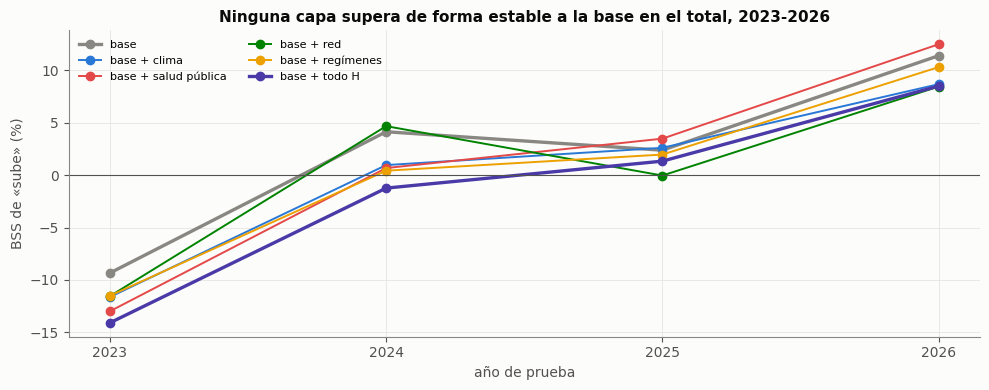

,años en que mejora a la base,mejora media del BSS (puntos),¿aporta? (≥ 3 de 4 años)
juego,,,
base + clima,1,-2.0,no
base + salud pública,2,-1.2,no
base + red,1,-1.8,no
base + regímenes,0,-1.8,no
base + todo H,0,-3.5,no


acierta sube/baja %                   BSS sube %       \
año                                 2023  2024  2025  2026       2023 2024   
juego                                                                        
base                                57.0  66.3  59.5  66.2       -9.3  4.1   
base + clima                        58.4  65.7  56.7  64.3      -11.6  1.0   
base + salud pública                55.3  65.4  60.0  63.1      -13.0  0.7   
base + red                          57.8  67.1  57.8  64.6      -11.5  4.7   
base + regímenes                    56.7  65.2  60.5  67.3      -11.5  0.4   
base + todo H                       58.1  64.0  58.6  61.2      -14.1 -1.2   

                                BSS pico %                cob80 %              \
año                  2025  2026       2023 2024 2025 2026    2023  2024  2025   
juego                                                                           
base                  2.4  11.4      -24.0  9.1  5.3  7.0    73.2  73.3  75.1   
base + clima          2.6   8.7      -32.1  8.1  7.1  6.9    72.3  75.3  74.2   
base + salud pública  3.5  12.5      -22.9  8.4  8.6  7.2    69.6  71.9  76.2   
base + red           -0.0   8.5      -17.7  7.7  5.2  1.6    67.4  74.7  72.3   
base + regímenes      2.0  10.3      -30.1  8.9  5.3  6.5    71.0  72.5  74.0   
base + todo H         1.3   8.5      -24.8  4.5  5.9  6.0    68.8  70.2  72.3   

                           MAPE %                 
año                   2026   2023 2024 2025 2026  
juego                                             
base                  74.5    9.1  8.8  8.5  9.0  
base + clima          74.5    9.2  9.1  8.5  9.0  
base + salud pública  74.5    9.1  9.1  8.5  8.9  
base + red            79.5    9.0  8.7  8.6  9.2  
base + regímenes      74.1    9.2  9.1  8.6  8.9  
base + todo H         76.4    9.0  9.3  8.6  9.3

In [6]:
B = M.loc["T0", "BSS sube %"].unstack("año").reindex(list(anual.JUEGOS))
mejora = B.sub(B.loc["base"], axis=1)
veredicto = pd.DataFrame({"años en que mejora a la base": (mejora > 0).sum(axis=1), "mejora media del BSS (puntos)": mejora.mean(axis=1).round(1),
                          "¿aporta? (≥ 3 de 4 años)": np.where((mejora > 0).sum(axis=1) >= 3, "SÍ", "no")}).drop("base")
fig, ax = plt.subplots(figsize=(10, 4))
for juego, c in zip(anual.JUEGOS, [MUDO, AZUL, ROJO, VERDE, AMARILLO, VIOLETA]):
    ax.plot(B.columns, B.loc[juego], "-o", color=c, lw=2.4 if juego in ("base", "base + todo H") else 1.4, label=juego)
ax.axhline(0, color=TINTA2, lw=.8); ax.set_xticks(B.columns); ax.set_xlabel("año de prueba"); ax.set_ylabel("BSS de «sube» (%)"); ax.legend(fontsize=8, ncol=2)
ax.set_title("Ninguna capa supera de forma estable a la base en el total, 2023-2026"); plt.tight_layout(); plt.show()
display(veredicto)
M.loc["T0", ["acierta sube/baja %", "BSS sube %", "BSS pico %", "cob80 %", "MAPE %"]].unstack("año").reindex(list(anual.JUEGOS)).round(1)

**Lectura.** **Con la regla fijada de antemano, ninguna capa externa aporta al pronóstico del total en 3 de 4 años.**

| Capa | Años que mejora a la base | Cambio medio del BSS (puntos) |
|---|---|---|
| Salud pública | 2 (2025 y 2026, +1,1 cada uno) | −1,2 |
| Clima | 1 | −2,0 |
| Red | 1 | −1,8 |
| Regímenes | 0 | −1,8 |
| Todo H junto | 0 | −3,5 |

El resultado coincide con la literatura en hospitales parecidos: en Porto Alegre los modelos con clima no superaron a los de calendario (Calegari et al., 2016) y en Londres los lineales igualaron o superaron a los de aprendizaje automático (Vollmer et al., 2021).

**Esto no equivale a decir que el contexto no importe.** Los cuadernos 17 a 21 midieron efectos reales: el clima mueve la IRA de la ciudad un 6-7 %, la lluvia reciente movió la banda de 65 años o más un 4,6 % en 2022-2024, efecto que no se confirmó en 2025-2026 y La Niña mueve las violencias. En el total esos efectos son de 1 a 3 %, por debajo del ruido diario del 12,6 %, y no son la IRA de la ciudad en pequeño (cuaderno 17). El argumento de dilución vale para lo que existe en una parte del hospital y pesa poco en el total. El contexto se ve en las partes (edad, motivo, aseguradora) y no en la suma. Que la salud pública mejore justo los dos años más recientes es la pista más consistente, y coincide con la literatura, donde el estado del sistema y de la epidemia ayuda más que el clima.

La base sola (calendario, estación, nivel y memoria) acierta 57,0, 66,3, 59,5 y 66,2 % en 2023-2026, con BSS de −9,3, +4,1, +2,4 y +11,4. Su media de acierto es de 62 %, dentro del rango creíble de 60-70 %. 2023 queda por debajo del calendario porque ese año se entrenó con 2020-2022, años de COVID.

---
# 7. Las técnicas de entrenamiento de la literatura, una por una

| | Técnica |
|---|---|
| T0 | Objetivo relativo al nivel (el método corregido) |
| T1 | T0 con peso 0,1 a los días COVID |
| T2 | T0 con más peso a lo reciente (vida media de 1,5 años) |
| T3 | T0 con peso doble a los contextos raros (crisis de la red, ola respiratoria, racha seca) |
| T4 | T0 con remuestreo de bloques de 28 días, 10 veces, y promedio |
| T5 | Todas las anteriores juntas |

Una técnica se adopta si mejora el BSS de «sube» frente a T0 en al menos 3 de los 4 años con todo el contexto H y sin
sacar la cobertura del 80 % del rango de 70 a 88 %. La definición de contexto raro de T3 excluye a El Niño y La Niña,
que juntos cubren el 67 % de los días de 2020-2026 y por tanto no son raros.

In [7]:
TEC = ["T0", "T1", "T2", "T3", "T4", "T5"]
filas = []
for j in ["base", "base + salud pública", "base + todo H"]:
    b = M.loc[(TEC, j), "BSS sube %"].unstack("año").droplevel(1)
    d = b.sub(b.loc["T0"], axis=1)
    cob = M.loc[(TEC, j), "cob80 %"].groupby(level=0).mean()
    for t in TEC[1:]:
        filas.append({"juego": j, "técnica": t, **{a: round(b.loc[t, a], 1) for a in b.columns}, "años que mejora a T0": int((d.loc[t] > 0).sum()),
                      "mejora media (puntos)": round(d.loc[t].mean(), 1), "cob80 media %": round(cob[t], 1),
                      "¿se adopta?": "SÍ" if (d.loc[t] > 0).sum() >= 3 and 70 <= cob[t] <= 88 else "no"})
TT = pd.DataFrame(filas).set_index(["juego", "técnica"])
display(M.loc[("T0", ["base", "base + salud pública", "base + todo H"]), "BSS sube %"].unstack("año").round(1))
TT

año                           2023  2024  2025  2026
tecnica juego                                       
T0      base                  -9.3   4.1   2.4  11.4
        base + salud pública -13.0   0.7   3.5  12.5
        base + todo H        -14.1  -1.2   1.3   8.5

2023  2024  2025  2026  años que mejora a T0  \
juego                técnica                                                 
base                 T1      -13.8   2.4  -3.3   6.3                     0   
                     T2       -8.3   6.7  -0.9   6.0                     2   
                     T3      -12.0   3.5   4.7  10.6                     1   
                     T4      -11.2   0.4  -0.3   9.1                     0   
                     T5      -14.5  -1.2  -7.6   1.1                     0   
base + salud pública T1      -13.0  -2.2  -3.2   6.1                     1   
                     T2      -11.7  -0.0  -1.8   5.9                     1   
                     T3      -14.0   0.4   4.9  12.1                     1   
                     T4      -13.2  -2.0  -0.8   8.7                     0   
                     T5      -15.3  -5.2  -8.2   0.5                     0   
base + todo H        T1      -16.8  -3.0  -4.5   2.4                     0   
                     T2      -13.4  -2.1  -4.0   1.8                     1   
                     T3      -10.4  -1.3   1.8   6.3                     2   
                     T4      -14.5  -5.2  -2.8   5.2                     0   
                     T5      -19.3  -7.0  -9.3  -5.4                     0   

                              mejora media (puntos)  cob80 media % ¿se adopta?  
juego                técnica                                                    
base                 T1                        -4.2           69.2          no  
                     T2                        -1.3           72.0          no  
                     T3                        -0.4           75.1          no  
                     T4                        -2.7           73.0          no  
                     T5                        -7.7           68.4          no  
base + salud pública T1                        -4.0           70.4          no  
                     T2                        -2.8           72.2          no  
                     T3                        -0.1           74.7          no  
                     T4                        -2.7           71.7          no  
                     T5                        -8.0           69.2          no  
base + todo H        T1                        -4.1           73.8          no  
                     T2                        -3.0           72.4          no  
                     T3                         0.5           74.5          no  
                     T4                        -2.9           73.6          no  
                     T5                        -8.9           69.8          no

**Lectura.** **Ninguna técnica cumple la regla de adopción, y la versión más simple (T0) es la mejor.**
- **T1, peso bajo al COVID:** empeora con todo H en los 4 años (de −1,8 a −6,1 puntos). Con la COVID ya marcada como variable, el modelo aprende de esos días sin copiar su forma, y quitarles peso solo le quita datos.
- **T2, más peso a lo reciente:** empeora en 3 de 4 años. Con solo seis años de historia, descontar el pasado deja demasiado poco.
- **T3, peso doble a contextos raros:** es la menos mala. Con todo H mejora 2 de 4 años (2023 +3,7 y 2025 +0,5) y su promedio es de +0,5 puntos. No cumple la regla, pero es la que convendría volver a probar con más historia.
- **T4, remuestreo de bloques:** empeora en 4 de 4. Bergmeir, Hyndman y Benítez (2016) lo probaron con suavizado exponencial, que se beneficia del bagging; un LightGBM ya promedia árboles y el remuestreo lo vuelve menos nítido.
- **T5, todo junto:** es la peor (de −5,2 a −13,9 puntos): los defectos se suman.

La literatura de combinaciones señala algo parecido: cada pieza estimada con pocos datos añade varianza (Wang, Hyndman, Li y Kang, 2023). El equivalente legítimo de «escoger y mezclar fechas» se probó y no mejora; queda descartado con evidencia.

---
# 8. Calibración de las probabilidades

El modelo emite una probabilidad de que el día sea más alto que lo esperado. Se examina qué probabilidades emite, si
se cumplen (calibración) y qué ocurre al recalibrarlas con el año anterior mediante la regresión logística de Platt.
Las probabilidades calibradas existen desde 2024, porque necesitan un año previo; las originales, desde 2023.
La figura muestra la distribución de las probabilidades, la curva de fiabilidad y el acierto según la seguridad con
que el modelo habla; las tablas siguientes dan los mismos datos en números.

años que mejora ¿se adopta?
tecnica juego                                            
T0      base                                1          no
        base + clima                        2          no
        base + red                          1          no
        base + regímenes                    2          no
        base + salud pública                1          no
        base + todo H                       1          no

sin calibrar (2023-2026)           con Platt (2024-2026)          
                                días acierta %                  días acierta %
50-60 %                          431      52.0                   686      57.4
60-70 %                          352      62.8                   409      57.2
70-80 %                          277      62.5                   231      63.6
más de 80 %                      289      68.2                    23      60.9

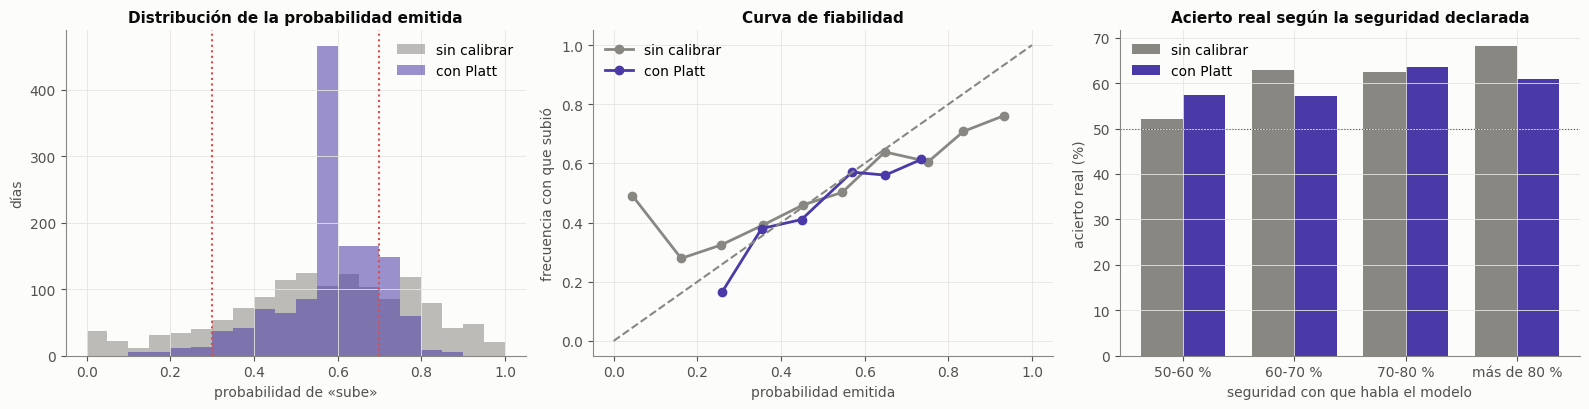

acierta sube/baja %                   BSS sube %       \
año                                  2023  2024  2025  2026       2023 2024   
tecnica juego                                                                 
T0      base                         55.3  65.4  52.1  66.2       -3.7  2.4   
        base + todo H                55.6  64.9  51.0  64.3       -7.4 -1.3   

                                 P > 0,70 %                 P < 0,30 %       \
año                   2025  2026       2023 2024  2025 2026       2023 2024   
tecnica juego                                                                 
T0      base           0.4  11.3       31.8  1.1  12.9  1.5        0.5  0.0   
        base + todo H -3.0   8.3       49.6  0.0  10.1  0.8        0.0  0.0   

                                  
año                   2025  2026  
tecnica juego                     
T0      base           3.3  14.4  
        base + todo H  1.4  11.0

In [8]:
PC = anual.platt(P)
MC = anual.metricas(PC, "p_cal")
cmp_ = pd.DataFrame({"Brier sin calibrar": M["Brier sube"], "Brier con Platt": MC["Brier sube"]}).dropna()
cmp_["mejora"] = cmp_["Brier sin calibrar"] > cmp_["Brier con Platt"]
cal_v = cmp_.groupby(level=[0, 1]).agg(**{"años que mejora": ("mejora", "sum")})
cal_v["¿se adopta?"] = np.where(cal_v["años que mejora"] >= 3, "SÍ", "no")
display(cal_v.loc[["T0"]])
D_ = PC[(PC.tecnica == "T0") & (PC.juego == "base + todo H")]
# seguridad del modelo = distancia de la probabilidad a 0,5
def por_banda(d, col):
    seg = np.abs(d[col] - .5) + .5
    g = pd.DataFrame({"ok": ((d[col] > .5) == (d.sube == 1)).values}).groupby(pd.cut(seg.values, [.5, .6, .7, .8, 1.]), observed=False).ok.agg(["size", "mean"])
    g.index = ["50-60 %", "60-70 %", "70-80 %", "más de 80 %"]; g["mean"] = (100 * g["mean"]).round(1)
    return g.rename(columns={"size": "días", "mean": "acierta %"})
Dsin = P[(P.tecnica == "T0") & (P.juego == "base + todo H") & (P["año"] >= 2023)]
tabla_bandas = pd.concat({"sin calibrar (2023-2026)": por_banda(Dsin, "p"), "con Platt (2024-2026)": por_banda(D_, "p_cal")}, axis=1)
display(tabla_bandas)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for col, c, et in [("p", MUDO, "sin calibrar"), ("p_cal", VIOLETA, "con Platt")]:
    axes[0].hist(D_[col], bins=np.linspace(0, 1, 21), color=c, alpha=.55, label=et)
    g = D_.groupby(pd.cut(D_[col], np.linspace(0, 1, 11)), observed=False).agg(p=(col, "mean"), f=("sube", "mean"), n=("sube", "size")).query("n >= 20")
    axes[1].plot(g.p, g.f, "-o", color=c, lw=2, label=et)
for x in (.3, .7): axes[0].axvline(x, color=ROJO, ls=":")
axes[0].set_xlabel("probabilidad de «sube»"); axes[0].set_ylabel("días"); axes[0].legend(); axes[0].set_title("Distribución de la probabilidad emitida")
axes[1].plot([0, 1], [0, 1], color=MUDO, ls="--"); axes[1].set_xlabel("probabilidad emitida"); axes[1].set_ylabel("frecuencia con que subió"); axes[1].legend()
axes[1].set_title("Curva de fiabilidad")
tb = tabla_bandas.values
w = .38; xx = np.arange(4)
axes[2].bar(xx - w / 2, tb[:, 1], w, color=MUDO, label="sin calibrar"); axes[2].bar(xx + w / 2, tb[:, 3], w, color=VIOLETA, label="con Platt")
axes[2].set_xticks(xx); axes[2].set_xticklabels(list(tabla_bandas.index)); axes[2].axhline(50, color=TINTA2, lw=.8, ls=":")
axes[2].set_xlabel("seguridad con que habla el modelo"); axes[2].set_ylabel("acierto real (%)"); axes[2].legend(); axes[2].set_title("Acierto real según la seguridad declarada")
plt.tight_layout(); plt.show()
MC.loc[("T0", ["base", "base + todo H"]), ["acierta sube/baja %", "BSS sube %", "P > 0,70 %", "P < 0,30 %"]].unstack("año").round(1)

**Lectura.** **Las probabilidades altas están exageradas.** Con T0 y todo H, en los 1.349 días de 2023-2026:

| El modelo dice estar | Días | Acierta de verdad |
|---|---|---|
| 50-60 % seguro | 431 | 52,0 % |
| 60-70 % | 352 | 62,8 % |
| 70-80 % | 277 | 62,5 % |
| **más de 80 %** | **289** | **68,2 %** |

Cuando el modelo declara más de 80 % de seguridad, acierta el 68,2 %; el techo real está entre 62 y 68 %. Platt con el año anterior (2024-2026) reduce los días de alta seguridad a 23, que aciertan el 60,9 %, pero los datos no justifican adoptarla: con T0 y todo H el Brier mejora en 1 de los 3 años evaluables, y las bandas de 50-70 % pasan a acertar el 57 % sin ganar resolución. Se pierde parte de la capacidad de distinguir días a cambio de corregir la exageración.

**Lectura práctica.** Un «70 % o más» del modelo equivale a un 65 % real, y un «50-60 %» equivale a lanzar una moneda. No se puede prometer una confianza por encima de 70 %, lo cual coincide con el rango que se considera creíble en este problema.

---
# 9. La corrección aplicada al motor con reentrenamiento semanal

La sección 5 encontró el error con un modelo congelado por año. Aquí se corrige en el motor (`lightgbm_rel`) y se
prueba con el protocolo habitual: reentrenar cada 7 días, decidir con 2025 y mirar 2026 una sola vez. C0 es la
combinación anterior (SARIMAX y LightGBM sobre el conteo) y C0r la corregida (SARIMAX y LightGBM sobre el desvío del
nivel).

In [9]:
import combinar as cb
def leer(exp, ms): P_, _ = pr.leer(ms, exp=exp); return P_
filas = {}
for etiqueta, exp in [("2025 · decide", "e1_2025"), ("2026 · prueba, una vez", "e1")]:
    T_ = cb.tabla(pd.concat([cb.promedio([leer(exp, ["sarimax"]), leer(exp, ["lightgbm"])], "C0"),
                             cb.promedio([leer(exp, ["sarimax"]), leer(exp, ["lightgbm_rel"])], "C0r")]))
    filas[etiqueta] = T_[["criterio (promedio BSS)", "acierta (28 dias) %", "acierta (rapida) %", "BSS pico (28 dias) %", "cob80 %", "MAPE %"]]
pd.concat(filas).round(1)

criterio (promedio BSS)  acierta (28 dias) %  \
                       modelo                                                 
2025 · decide          C0                          4.2                 59.9   
                       C0r                         5.2                 61.9   
2026 · prueba, una vez C0                         15.2                 69.4   
                       C0r                        15.9                 69.6   

                               acierta (rapida) %  BSS pico (28 dias) %  \
                       modelo                                             
2025 · decide          C0                    58.3                   4.3   
                       C0r                   59.5                   2.9   
2026 · prueba, una vez C0                    64.1                  16.5   
                       C0r                   64.3                  15.0   

                               cob80 %  MAPE %  
                       modelo                   
2025 · decide          C0         78.0     8.6  
                       C0r        80.5     8.5  
2026 · prueba, una vez C0         80.3     8.9  
                       C0r        81.1     8.8

**Lectura.** **C0r reemplaza a C0**, decidido con 2025 por la regla fijada de antemano:

| 2025 (decide) | C0 | **C0r** |
|---|---|---|
| Criterio (promedio del BSS de sube, dos varas) | 4,2 | **5,2** |
| Acierto en sube/baja (vara de 28 días) | 59,9 % | **61,9 %** |
| Cobertura del 80 % | 78,0 % | **80,5 %** |
| MAPE | 8,6 % | **8,5 %** |

En 2026, mirado una sola vez, queda casi igual: criterio 15,9 contra 15,2 y acierto de 69,6 % contra 69,4 %; la cobertura es de 81,1 % contra 80,3 %. Con reentrenamiento semanal la corrección apenas cambia el acierto; su aporte es eliminar el riesgo de colapso cuando el nivel sale de lo conocido, que con el modelo congelado costó 100 puntos de BSS (sección 5).

---
# 10. Entrenar con fechas escogidas y con pesos por tipo de contexto

Una forma de dar al modelo contexto de todo tipo es controlar con qué registros se entrena. Se descartó mezclar al azar
(sección 3) y se probó la versión controlada y marcada: escoger fechas importantes y fechas estables, o pesar cada tipo de
contexto por igual. Las variables ya estaban medidas en los cuadernos 17 a 21; lo que se ajusta es el conjunto de
entrenamiento.

Las marcas (`notebooks/marcas.py`) salen solo del calendario y de las variables externas, nunca del triage: marcar los
picos del propio triage le enseñaría al modelo a esperar picos.

| Marca | Cuándo |
|---|---|
| Calendario especial | festivo, puente, víspera, día después, Semana Santa, fin de año |
| Transición de clima | paso de seco a lluvioso en los últimos 7 días, o cambio brusco por encima del percentil 95 |
| Clima extremo | racha seca de más de 14 días, o semana muy lluviosa |
| Ola de salud pública | respiratoria > 1 desviación; violencias, salud mental, materno-perinatal > 1,5; inmunoprevenibles > 2 |
| Red de salud | resolución de la Supersalud en los últimos 30 días, o cambio de Nueva EPS por encima del percentil 95 |
| El Niño / La Niña fuerte | ONI de 1,5 o más (en valor absoluto) |
| Sismo | M ≥ 4,5 a menos de 150 km en los últimos 7 días |
| COVID | marzo de 2020 a febrero de 2022 |

Tres diseños: S0, todos los días con el mismo peso; S1, todos los días, pero cada tipo de contexto pesa lo mismo; S2,
escoger fechas (todas las marcadas, el COVID uno de cada tres días y los estables uno de cada dos, en orden de fecha). Se
mide donde importa: en los días marcados del año de prueba, y aparte en los estables.

In [10]:
import marcas
MK = marcas.marcar(pd.date_range("2020-01-01", "2026-09-20"))
display(MK.groupby(MK.index.year).sum().T.rename_axis("días por año"))
rec = MK.loc["2022-01-01":]
share = (100 * rec.mean()).round(1).rename("% de los días, 2022-2026").to_frame()
display(share.T)
PCU = pd.read_parquet(RAIZ / "salidas/pronostico/anual_curado.parquet")
TC, VC, TIP = anual.evaluar_curado(PCU)
TC["BSS marcados"].unstack("año").loc[["S0", "S1", "S2"]].round(1)

,2020,2021,2022,2023,2024,2025,2026
días por año,,,,,,,
calendario especial,70,72,72,72,69,67,47
transición de clima,88,42,44,91,104,62,29
clima extremo,63,44,55,34,60,50,24
ola de salud pública,49,91,119,35,70,7,0
red de salud,65,1,23,0,34,110,136
El Niño / La Niña fuerte,0,0,0,61,121,0,20
sismo,28,21,28,39,28,28,44
COVID,292,365,59,0,0,0,0
estable,9,0,93,142,75,130,76


,calendario especial,transición de clima,clima extremo,ola de salud pública,red de salud,El Niño / La Niña fuerte,sismo,COVID,estable
"% de los días, 2022-2026",19.0,19.1,12.9,13.4,17.6,11.7,9.7,3.4,29.9


año                           2023  2024  2025  2026
tecnica juego                                       
S0      base                  -7.9   4.7   5.4  11.2
        base + salud pública  -9.1   2.0   6.2  13.0
        base + todo H         -8.6  -0.5   5.4   9.9
S1      base                  -7.6   4.9   4.1  10.7
        base + salud pública  -9.1   1.4   4.3  11.4
        base + todo H        -10.5  -2.2   3.3   8.7
S2      base                 -19.8   0.6  -1.2   9.4
        base + salud pública -22.6  -2.0  -1.5  10.0
        base + todo H        -24.7  -5.7  -4.7   4.0

In [11]:
display(VC.loc[["S0", "S1", "S2"]])
TC["BSS estables"].unstack("año").loc[["S0", "S1", "S2"]].round(1)

años que mejora en marcados  \
diseño juego                                               
S0     base + salud pública                            2   
       base + todo H                                   1   
S1     base                                            2   
       base + salud pública                            1   
       base + todo H                                   0   
S2     base                                            0   
       base + salud pública                            0   
       base + todo H                                   0   

                             mejora media en marcados  \
diseño juego                                            
S0     base + salud pública                      -0.3   
       base + todo H                             -1.8   
S1     base                                      -0.3   
       base + salud pública                      -1.4   
       base + todo H                             -3.5   
S2     base                                      -6.1   
       base + salud pública                      -7.4   
       base + todo H                            -11.1   

                             cambio medio en estables ¿sirve?  
diseño juego                                                   
S0     base + salud pública                      -3.2      no  
       base + todo H                             -6.8      no  
S1     base                                      -1.8      no  
       base + salud pública                      -5.2      no  
       base + todo H                             -7.9      no  
S2     base                                      -6.5      no  
       base + salud pública                      -8.7      no  
       base + todo H                            -11.1      no

año                           2023  2024  2025  2026
tecnica juego                                       
S0      base                 -11.7   1.8  -5.5  11.3
        base + salud pública -19.2  -4.6  -3.9  10.8
        base + todo H        -22.8  -4.5  -8.5   4.4
S1      base                 -18.2   3.3  -9.2  12.7
        base + salud pública -23.6  -4.9  -7.2  10.7
        base + todo H        -21.5  -6.3 -10.7   2.8
S2      base                 -16.7  -3.4 -15.8   6.0
        base + salud pública -20.3  -8.4 -12.3   2.1
        base + todo H        -20.9 -13.6 -15.4   1.3

**Lectura.** **Casi siempre hay algún contexto activo.** En 2022-2026 solo el 29,9 % de los días es estable. Cada tipo de contexto marca entre el 3,4 % (COVID) y el 19,1 % de los días, y se solapan, por lo que escoger «todas las marcadas y una muestra de estables» cambia poco la mezcla.

**Ningún diseño cumple la regla** (mejorar en los días marcados en al menos 3 de 4 años sin perder más de 2 puntos en los estables):
- **S2, escoger fechas, empeora todo.** En los días marcados pierde de 6,1 a 11,1 puntos de BSS. Quitar días le quita ejemplos a un modelo que tiene pocos.
- **S1, equilibrar por peso, queda casi neutro con la base** (−0,3 puntos en los marcados) y pierde 3,5 puntos en los marcados con todo H.

**La pista está en los días estables.** Con las 24 variables siempre encendidas (S0, todo H), el modelo pierde 6,8 puntos en promedio justo donde el contexto no tiene nada que decir: usa las variables para ajustar ruido. El problema no es qué fechas ve el modelo, sino que las variables están siempre encendidas.

---
# 11. El contexto con compuerta

La sección 10 dejó una pista: con las 24 variables el modelo empeora en los días estables, donde el contexto no debería
hacer nada. Con unos 2.400 días de historia, las usa para explicar el ruido de días tranquilos.

La respuesta sigue un principio de mecanismos: cada factor tiene su gatillo. Cada capa se enciende solo cuando su
gatillo está activo y en el resto de los días queda apagada (valor faltante), de modo que no puede ajustar ruido:

| Capa | Se enciende con |
|---|---|
| Clima | transición de clima o clima extremo |
| Salud pública | ola de salud pública |
| Red de salud | movimiento en la red |
| Regímenes | El Niño o La Niña fuerte, o sismo |

Además entran las 8 marcas como variables. G1 es la compuerta con todos los días; G2, con los pesos de S1.

In [12]:
sel = [("S0", "base"), ("S0", "base + todo H"), ("G1", "base + salud pública"), ("G1", "base + todo H"), ("G2", "base + salud pública"), ("G2", "base + todo H")]
display(VC.loc[["G1", "G2"]])
pd.concat({c: TC[c].unstack("año").loc[sel] for c in ["BSS todos", "acierta todos %", "cob80 %"]}, axis=1).round(1)

años que mejora en marcados  \
diseño juego                                               
G1     base + salud pública                            3   
       base + todo H                                   1   
G2     base + salud pública                            1   
       base + todo H                                   0   

                             mejora media en marcados  \
diseño juego                                            
G1     base + salud pública                       1.3   
       base + todo H                             -0.9   
G2     base + salud pública                      -0.7   
       base + todo H                             -2.3   

                             cambio medio en estables ¿sirve?  
diseño juego                                                   
G1     base + salud pública                      -0.8      SÍ  
       base + todo H                             -2.0      no  
G2     base + salud pública                      -4.5      no  
       base + todo H                             -3.9      no

BSS todos                 acierta todos %        \
año                               2023 2024 2025  2026            2023  2024   
tecnica juego                                                                  
S0      base                      -9.3  4.1  2.4  11.4            57.0  66.3   
        base + todo H            -14.1 -1.2  1.3   8.5            58.1  64.0   
G1      base + salud pública      -7.7  4.1  2.7  11.4            59.7  67.4   
        base + todo H            -10.4  0.9  1.6  11.9            56.2  65.4   
G2      base + salud pública     -13.2  3.9 -0.3  10.0            56.7  66.3   
        base + todo H            -13.0  2.2 -0.9   8.8            56.4  65.7   

                                         cob80 %                    
año                           2025  2026    2023  2024  2025  2026  
tecnica juego                                                       
S0      base                  59.5  66.2    73.2  73.3  75.1  74.5  
        base + todo H         58.6  61.2    68.8  70.2  72.3  76.4  
G1      base + salud pública  59.7  66.2    71.5  72.2  75.6  74.5  
        base + todo H         58.6  66.5    71.0  72.2  74.5  74.9  
G2      base + salud pública  56.7  63.9    67.1  72.2  74.0  73.8  
        base + todo H         56.7  65.4    67.1  73.0  72.9  75.7

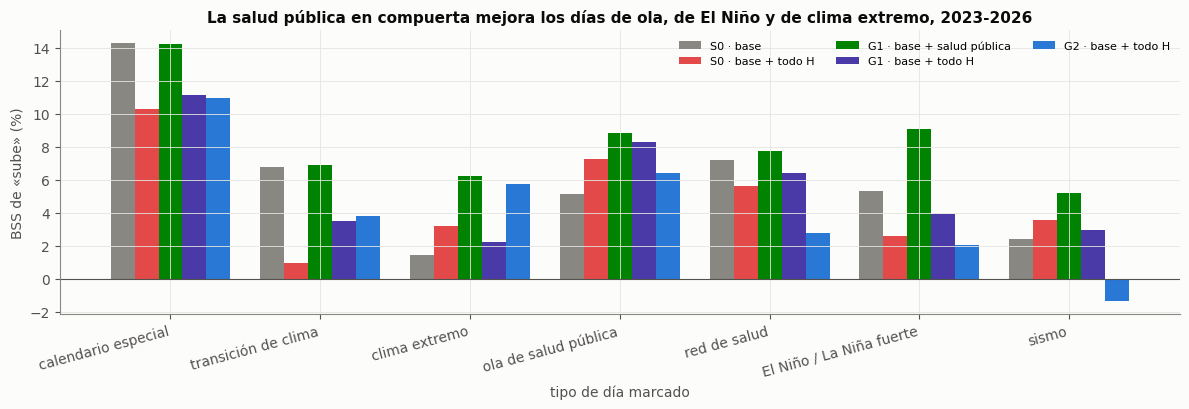

,S0 · base,S0 · base + todo H,G1 · base + salud pública,G1 · base + todo H,G2 · base + todo H
calendario especial,14.3,10.3,14.2,11.1,10.9
transición de clima,6.8,1.0,6.9,3.5,3.8
clima extremo,1.4,3.2,6.2,2.2,5.7
ola de salud pública,5.1,7.2,8.8,8.3,6.4
red de salud,7.2,5.6,7.7,6.4,2.8
El Niño / La Niña fuerte,5.3,2.6,9.1,3.9,2.0
sismo,2.4,3.6,5.2,3.0,-1.4


In [13]:
cols = ["S0 · base", "S0 · base + todo H", "G1 · base + salud pública", "G1 · base + todo H", "G2 · base + todo H"]
fig, ax = plt.subplots(figsize=(12, 4.2)); T_ = TIP[cols]; x = np.arange(len(T_))
for k, (c, col) in enumerate(zip(cols, [MUDO, ROJO, VERDE, VIOLETA, AZUL])):
    ax.bar(x + (k - 2) * .16, T_[c], .16, color=col, label=c)
ax.axhline(0, color=TINTA2, lw=.8); ax.set_xticks(x); ax.set_xticklabels(T_.index, rotation=15, ha="right"); ax.set_ylabel("BSS de «sube» (%)")
ax.set_xlabel("tipo de día marcado")
ax.legend(fontsize=8, ncol=3); ax.set_title("La salud pública en compuerta mejora los días de ola, de El Niño y de clima extremo, 2023-2026"); plt.tight_layout(); plt.show()
T_.round(1)

**Lectura.** **La compuerta funciona y es la primera vez en este cuaderno que el contexto mejora el pronóstico del total de forma estable en la rejilla anual.**
- **G1 con salud pública cumple la regla.** En los días marcados mejora 3 de 4 años (+1,3 puntos de media) y en los estables pierde poco (−0,8). En todos los días iguala o mejora a la base los 4 años: BSS −7,7 / +4,1 / +2,7 / +11,4 contra −9,3 / +4,1 / +2,4 / +11,4, con un acierto de 59,7 / 67,4 / 59,7 / 66,2 %.
- **Con las 24 variables en compuerta el daño casi desaparece**, aunque no cumple la regla. En 2026 el acierto pasa de 61,2 % sin compuerta a 66,5 %, igual al de la base.

**En qué tipo de día ayuda** (BSS de «sube», 2023-2026):

| Tipo de día | Base | Salud pública en compuerta (G1) | Las 24 en compuerta (G1) |
|---|---|---|---|
| Ola de salud pública | +5,1 | **+8,8** | +8,3 |
| El Niño o La Niña fuerte | +5,3 | **+9,1** | +3,9 |
| Clima extremo | +1,4 | **+6,2** | +2,2 |
| Sismo | +2,4 | **+5,2** | +3,0 |
| Red de salud | +7,2 | +7,7 | +6,4 |
| Transición de clima | +6,8 | +6,9 | +3,5 |
| Calendario especial | +14,3 | +14,2 | +11,1 |

La salud pública en compuerta iguala o mejora a la base en los 7 tipos de día (en calendario especial, con −0,1 de diferencia). Ayuda más donde era esperable: olas, El Niño o La Niña fuerte (el cuaderno 20 encontró que La Niña mueve violencias y salud mental) y clima extremo. Las otras capas, aun con compuerta, siguen restando en transiciones de clima y en días de calendario; con pocos episodios de cada tipo aportan más ruido que señal en el total, y su lugar probable son las bandas de edad, donde el efecto medido es mayor.

El resultado coincide con la literatura de urgencias, en la que el estado de la epidemia es lo que más se ha usado con éxito, y con el principio de mecanismos: cada factor tiene su gatillo, y fuera de él es ruido.

---
# 12. La confirmación de la compuerta con origen rodante

Lo observado en la rejilla anual se confirma con origen rodante, reentrenando cada 7 días como opera el modelo: Cg es
SARIMAX y LightGBM con la salud pública en compuerta. Se decide con 2025 contra C0r y se mira 2026 una sola vez. Se
muestra además el número de días de ola de salud pública de cada año, que determina cuántas veces estuvo encendida
la compuerta.

In [14]:
filas = {}
for etiqueta, e1, g in [("2025 · decide", "e1_2025", "g_2025"), ("2026 · prueba, una vez", "e1", "g")]:
    T_ = cb.tabla(pd.concat([cb.promedio([leer(e1, ["sarimax"]), leer(e1, ["lightgbm_rel"])], "C0r"),
                             cb.promedio([leer(e1, ["sarimax"]), leer(g, ["lightgbm_rel"])], "Cg")]))
    filas[etiqueta] = T_[["criterio (promedio BSS)", "acierta (28 dias) %", "acierta (rapida) %", "BSS pico (28 dias) %", "cob80 %", "MAPE %"]]
display(pd.concat(filas).round(1))
MK.groupby(MK.index.year)["ola de salud pública"].sum().loc[2023:2026].to_frame("días de ola de salud pública").T

criterio (promedio BSS)  acierta (28 dias) %  \
                       modelo                                                 
2025 · decide          C0r                         5.2                 61.9   
                       Cg                          5.1                 61.5   
2026 · prueba, una vez C0r                        15.9                 69.6   
                       Cg                         15.4                 68.6   

                               acierta (rapida) %  BSS pico (28 dias) %  \
                       modelo                                             
2025 · decide          C0r                   59.5                   2.9   
                       Cg                    58.9                   3.8   
2026 · prueba, una vez C0r                   64.3                  15.0   
                       Cg                    63.6                  14.8   

                               cob80 %  MAPE %  
                       modelo                   
2025 · decide          C0r        80.5     8.5  
                       Cg         79.7     8.5  
2026 · prueba, una vez C0r        81.1     8.8  
                       Cg         80.5     8.9

,2023,2024,2025,2026
días de ola de salud pública,35,70,7,0


**Lectura.** **Con origen rodante, la compuerta empata con C0r, y por la regla se mantiene C0r.**

| | C0r (sin contexto) | Cg (salud pública en compuerta) |
|---|---|---|
| 2025, decide: criterio | **5,2** | 5,1 |
| 2025: acierto (vara de 28 días) | 61,9 % | 61,5 % |
| 2025: BSS de pico | 2,9 | **3,8** |
| 2026, una vez: criterio | **15,9** | 15,4 |
| 2026: acierto (vara de 28 días) | 69,6 % | 68,6 % |
| 2026: BSS de pico | 15,0 | 14,8 |

Las diferencias de acierto son de −0,4 puntos en 2025 y de −1,0 en 2026, y la cobertura del 80 % se mantiene entre 79,7 y 80,5 % para Cg.

**La confirmación no se logra porque en esos años casi no hubo olas.** La ola de salud pública marcó 35 días en 2023 y 70 en 2024, pero 7 en 2025 y 0 en 2026. La compuerta estuvo apagada casi todo el tiempo, y con reentrenamiento semanal el nivel y la memoria absorben lo poco que queda. La ganancia de la rejilla anual venía de 2023 y 2024, que sí traen olas.

El resultado ni confirma ni refuta la compuerta: los años de prueba no contienen el contexto en que debía actuar. C0r es el modelo principal. Cg queda como hipótesis prospectiva, que se pone a prueba comparando su predicción semanal con la de C0r cuando ocurra una ola respiratoria; la temporada de lluvias de octubre y noviembre es la candidata.

---
# 13. La respuesta semanal: método y alcance

El producto operativo del modelo es una respuesta por semana: la media diaria esperada, el rango y la probabilidad de que
cada día quede por encima de lo normal. El script `notebooks/semana.py` la construye con el modelo principal C0r
(SARIMAX y LightGBM sobre el desvío del nivel, entrenados desde 2020 con calendario, estación, nivel y memoria) y puede
anticiparse hasta tres semanas, porque los datos disponibles van unos 15 días por detrás de la fecha en que se pregunta.

- «Lo normal» de cada día es el control de calendario más el nivel de 28 días.
- El rango de la semana sale de una cópula gaussiana entre sus siete días, con la correlación medida en la validación
  de 2025, de modo que el rango del total semanal no suma como si los días fueran independientes.
- También se reparte el día por franjas (mañana y tarde).
- La predicción se guarda antes de conocer lo real y no se rehace; su valor como prueba prospectiva depende de
  haberse escrito antes. Junto a la de C0r se guarda la de Cg, para compararlas cuando ocurra una ola respiratoria.

La misma respuesta puede rehacerse en cada domingo de 2025 y 2026, con la semana siguiente y con la semana que empieza
15 días después. Esa validación semanal no tiene resultados guardados en el momento de este cuaderno, y por eso aquí
no se reporta ninguna cifra de acierto semanal; lo medido sobre el acierto diario con el mismo modelo es el de las
secciones 9 y 12.

---
# 14. Conclusiones y límites

**Hallazgos.**

1. **Catálogo.** De 22 grupos de variables, 15 entran y 7 quedan fuera. Entra lo que se conoce el día de la predicción, tiene historia y no se construyó mirando 2026.
2. **La partición aleatoria no es válida.** Infla el acierto de 7 a 9 puntos y hace parecer útiles variables que empeoran el pronóstico real.
3. **Un error de método** se encontró y corrigió: el árbol debe aprender el desvío frente al nivel (C0r, adoptado con 2025), porque un árbol no extrapola fuera del rango visto.
4. **La confiabilidad honesta es de alrededor del 62 %** de acierto en sube/baja en cuatro años distintos. Las probabilidades declaradas por encima de 80 % acertaron el 68,2 %; hay que presentarlas comprimidas.
5. **Cada factor tiene su gatillo.** Con las variables siempre encendidas, el modelo empeora en los días estables; con compuerta, la salud pública mejora el pronóstico del total en 3 de 4 años en la rejilla anual y ayuda en olas, en El Niño o La Niña fuertes y en clima extremo.
6. **Escoger fechas no ayuda, y encender las variables en el momento justo sí**, en la rejilla anual. Con origen rodante la compuerta empata con C0r.
7. **Las técnicas genéricas de la literatura** (peso al COVID, recencia, remuestreo) no superan a la versión simple.

**Límites.**
- **Pocos episodios.** La confirmación con origen rodante no pudo separar la compuerta de C0r porque 2025 trajo 7 días de ola y 2026 ninguno. El diseño no tenía cómo ver el efecto, y por eso no se concluye que no exista.
- **Contextos nuevos.** La crisis de la red aparece 263 días en 2026 y el entrenamiento solo vio 170; hay contextos de los que no se puede aprender más que lo ya ocurrido.
- **El total achica lo que ocurre en las partes.** Los efectos medidos en las partes (por ejemplo, por banda de edad en el cuaderno 21) son mayores que en la suma; este cuaderno solo evalúa el total.
- **Calibración.** Platt solo se evalúa en 3 años (2024-2026), de modo que la regla de 3 de 4 años no aplica del todo a ella.
- **Clima observado.** Las entradas de clima de la validación son observaciones y no pronósticos, de modo que lo medido es un techo de lo que se tendría en operación.
- **Respuesta semanal.** La validación semanal no tiene resultados guardados en el momento de este cuaderno, por lo que el acierto semanal no está verificado contra datos posteriores.

---
# Referencias

Cada referencia se comprobó contra su registro en Crossref (autores, año, revista y DOI).

- Asheim, A., Bache-Wiig Bjørnsen, L. P., Næss-Pleym, L. E. y Uleberg, O. (2019). Real-time forecasting of emergency department arrivals using prehospital data. *BMC Emergency Medicine*, 19. https://doi.org/10.1186/s12873-019-0256-z
- Bergmeir, C., Hyndman, R. J. y Benítez, J. M. (2016). Bagging exponential smoothing methods using STL decomposition and Box-Cox transformation. *International Journal of Forecasting*, 32(2). https://doi.org/10.1016/j.ijforecast.2015.07.002
- Bergmeir, C., Hyndman, R. J. y Koo, B. (2018). A note on the validity of cross-validation for evaluating autoregressive time series prediction. *Computational Statistics & Data Analysis*, 120, 70-83. https://doi.org/10.1016/j.csda.2017.11.003
- Calegari, R., Fogliatto, F. S., Lucini, F. R. y Neyeloff, J. (2016). Forecasting daily volume and acuity of patients in the emergency department. *Computational and Mathematical Methods in Medicine*, 2016. https://doi.org/10.1155/2016/3863268
- Cerqueira, V., Torgo, L. y Mozetič, I. (2020). Evaluating time series forecasting models: an empirical study on performance estimation methods. *Machine Learning*, 109. https://doi.org/10.1007/s10994-020-05910-7
- Diebold, F. X. y Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253-263. https://doi.org/10.1080/07350015.1995.10524599
- Giacomini, R. y White, H. (2006). Tests of conditional predictive ability. *Econometrica*, 74(6). https://doi.org/10.1111/j.1468-0262.2006.00718.x
- Hansen, P. R., Lunde, A. y Nason, J. M. (2011). The model confidence set. *Econometrica*, 79(2), 453-497. https://doi.org/10.3982/ECTA5771
- Hewamalage, H., Ackermann, K. y Bergmeir, C. (2023). Forecast evaluation for data scientists: common pitfalls and best practices. *Data Mining and Knowledge Discovery*, 37, 788-832. https://doi.org/10.1007/s10618-022-00894-5
- Hyndman, R. J. y Rostami-Tabar, B. (2025). Forecasting interrupted time series. *Journal of the Operational Research Society*, 76, 790-803. https://doi.org/10.1080/01605682.2024.2395315
- Kull, M., Silva Filho, T. M. y Flach, P. (2017). Beyond sigmoids: how to obtain well-calibrated probabilities from binary classifiers with beta calibration. *Electronic Journal of Statistics*, 11. https://doi.org/10.1214/17-EJS1338SI
- Lichtendahl, K. C., Grushka-Cockayne, Y. y Winkler, R. L. (2013). Is it better to average probabilities or quantiles? *Management Science*. https://doi.org/10.1287/mnsc.1120.1667
- López de Prado, M. (2018). *Advances in Financial Machine Learning*. Wiley.
- Montero-Manso, P. y Hyndman, R. J. (2021). Principles and algorithms for forecasting groups of time series: locality and globality. *International Journal of Forecasting*, 37. https://doi.org/10.1016/j.ijforecast.2021.03.004
- Murtas, R., Tunesi, S., Andreano, A. et al. (2022). Time-series cohort study to forecast emergency department visits in the city of Milan and predict high demand. *BMJ Open*, 12. https://doi.org/10.1136/bmjopen-2021-056017
- Niculescu-Mizil, A. y Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of the 22nd International Conference on Machine Learning*. https://doi.org/10.1145/1102351.1102430
- Pesaran, M. H., Pick, A. y Pranovich, M. (2013). Optimal forecasts in the presence of structural breaks. *Journal of Econometrics*. https://doi.org/10.1016/j.jeconom.2013.04.002
- Racine, J. (2000). Consistent cross-validatory model-selection for dependent data: hv-block cross-validation. *Journal of Econometrics*, 99. https://doi.org/10.1016/S0304-4076(00)00030-0
- Sugiyama, M., Krauledat, M. y Müller, K.-R. (2007). Covariate shift adaptation by importance weighted cross validation. *Journal of Machine Learning Research*, 8, 985-1005. https://jmlr.org/papers/v8/sugiyama07a.html
- Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: an analysis and review. *International Journal of Forecasting*, 16. https://doi.org/10.1016/S0169-2070(00)00065-0
- Tuominen, J., Lomio, F., Oksala, N. y Palomäki, A. (2022). Forecasting daily emergency department arrivals using high-dimensional multivariate data: a feature selection approach. *BMC Medical Informatics and Decision Making*, 22. https://doi.org/10.1186/s12911-022-01878-7
- Vollmer, M. A. C., Glampson, B., Mellan, T. et al. (2021). A unified machine learning approach to time series forecasting applied to demand at emergency departments. *BMC Emergency Medicine*, 21. https://doi.org/10.1186/s12873-020-00395-y
- Wang, X., Hyndman, R. J., Li, F. y Kang, Y. (2023). Forecast combinations: an over 50-year review. *International Journal of Forecasting*, 39, 1518-1547. https://doi.org/10.1016/j.ijforecast.2022.11.005
- Wargon, M., Guidet, B., Hoang, T. D. y Hejblum, G. (2009). A systematic review of models for forecasting the number of emergency department visits. *Emergency Medicine Journal*, 26, 395-399. https://doi.org/10.1136/emj.2008.062380